# 토큰과 중간 진행 스트리밍

**이 노트북에서 할 일**

1. 노드 안에서 실제 모델을 부르는 그래프를 만들고, 모델 요청 앞뒤에 진행 값을 보냅니다.
2. 모드 셋(`messages`·`updates`·`custom`)을 한 실행에서 함께 받아, 사건이 나온 차례를 봅니다.
3. 스트림 청크와 칸 `metadata`를 읽고, 이어 붙인 글이 최종 답 글과 같은지 확인합니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 3절과 8절에서 한 번씩, 모두 2번입니다.
요금표로 어림한 예상 비용은 두 요청을 합쳐 0.001달러 아래이고, 청구 금액이 아닙니다.
모델의 답 글과 스트림 청크 수는 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

읽거나 쓰는 파일은 없고, 체크포인터도 쓰지 않습니다.
01절에서 배운 함수 둘은 도구 파일 `stream_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
모델을 부르는 노드를 만들고, 세 모드를 함께 받아 사건 차례와 스트림 청크를 보는 자리입니다.
6~8절은 칸 `metadata`, 스트림 청크 이어 붙이기, 모드를 뺀 실행을 보는 자리이고 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch25-streaming`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 입력 칸 question 배송 문의 한 줄이 회색 상자 graph.stream 모드 셋을 한 목록으로를 거쳐 파란 상자 노드 write_answer 요청 앞뒤에 진행 값으로 이어집니다. 파란 상자에서 보라 상자 모델 gpt-5.4-mini 노드 안 invoke 한 번, 노란 상자 custom 진행 값 둘 30과 100, 노란 상자 updates 갱신 하나로 화살표가 갑니다. 보라 상자 아래 노란 상자 messages 스트림 청크 여러 개가 있는 그림](attachment:02-1-한-실행에서-함께-받은-세-모드.png)

위에서 아래로 읽습니다.
초록 상자는 넣은 입력, 회색 상자는 라이브러리 메서드, 파란 상자는 우리가 적은 노드입니다.
보라 상자는 이 절에서 실제로 부른 모델이고, 노란 상자는 노트북 3·4절에서 출력으로 확인한 값입니다.
스트림 청크는 모델에서, 진행 값과 갱신은 노드에서 나옵니다.
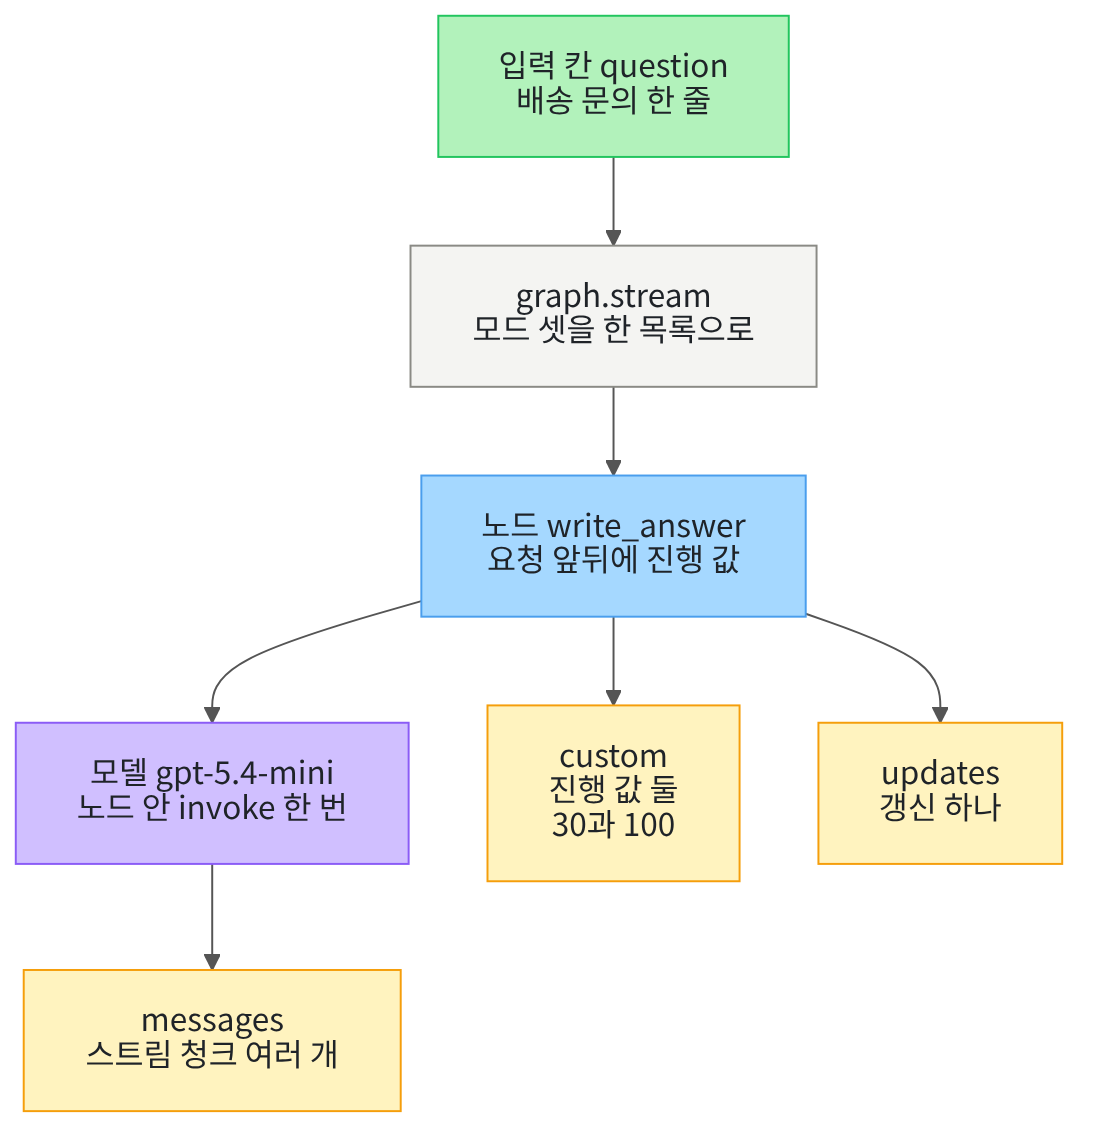

## 1. 준비

01절은 모델 없이 노드 둘짜리 그래프를 실행했고, 모드 `messages`의 사건은 0개였습니다.
이 절에서는 노드 안에서 실제 모델을 불러, 그 모드로 모델의 답을 받습니다.
절 제목의 중간 진행은 01절에서 정한 진행 값이고, 이번에도 모드 `custom`으로 받습니다.
제목의 토큰 스트리밍이 무엇을 받는 일인지는 5절에서 풉니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langgraph: 1.2.11`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모델을 만드는 함수 `init_chat_model`은 Ch 6 01절, 상태 형식과 그래프 이름은 Ch 13 01절과 같습니다.
함수 `get_stream_writer`는 01절에서 진행 값을 보낼 때 썼습니다.
마지막 가져오기 줄은 01절에서 배운 함수 둘을 도구 파일 `stream_tools.py`에서 가져옵니다.

In [2]:
# 모델(Ch 6 01절)·그래프(Ch 13 01절)를 만드는 이름과, 진행 값을 보낼 쓰기 함수를 가져옵니다
from typing_extensions import TypedDict
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END
from langgraph.config import get_stream_writer
# 01절에서 배운 함수 둘은 도구 파일에서 가져옵니다
from stream_tools import collect_events, positions_of

print("도구 파일에서 가져온 함수:", "collect_events, positions_of")

도구 파일에서 가져온 함수: collect_events, positions_of


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: collect_events, positions_of`가 보입니다.
함수 `collect_events`는 그래프를 한 번 실행하며 받은 사건을 목록에 모아 내놓습니다.
함수 `positions_of`는 한 모드의 사건이 몇 번째(1부터 셈)에 나왔는지 목록으로 내놓습니다.
두 함수 모두 01절 노트북 4절에서 처음 적었습니다.

앞에서 배운 함수는 `stream_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.

## 2. 모델을 부르는 노드

01절 노드 `write`는 문의 제목 뒤에 글을 붙여 안내 초안을 만들었습니다.
이 절의 노드는 배송 문의에 답하는 안내 문장을 모델에게 쓰게 합니다.
먼저 상태 형식을 만듭니다.
칸 `question`은 문의 글, 칸 `answer`는 모델이 쓴 답 글입니다.
칸 구성이 01절과 달라, 상태 형식에도 새 이름을 붙입니다.

In [5]:
# 문의 글과 모델이 쓴 답 글 칸을 둔 상태 형식을 만듭니다(Ch 13 01절 모양, 두 칸 모두 규칙 없음)
class AnswerState(TypedDict):
    question: str
    answer: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 절의 그래프가 이 상태 형식을 씁니다.

다음 셀은 모델에게 줄 시스템 메시지 글을 정합니다.
Ch 6 04절처럼 메시지 목록의 첫 튜플에 역할 `system`과 함께 넣을 글입니다.

In [6]:
# 모델에게 줄 시스템 메시지 글을 정합니다(답을 두 문장으로 짧게 받으려고)
system_text = "배송 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요."
print("시스템 메시지 글:", system_text)

시스템 메시지 글: 배송 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요.


**결과 읽기** — 출력 줄 `시스템 메시지 글: 배송 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요.`가 보입니다.
답을 두 문장으로 부탁해, 모델의 답이 짧게 끝나게 했습니다.

다음 셀은 이 절의 노드입니다.
01절처럼 `writer = get_stream_writer()`로 쓰기 함수를 꺼내, 모델 요청 앞뒤에 진행 값을 하나씩 보냅니다.
요청 앞에는 `{"stage": "before_model", "progress": 30}`, 요청 뒤에는 진행 값 100을 보냅니다.
모델 요청은 노드 안의 `model.invoke(messages)` 한 줄에서 나갑니다.

In [7]:
# 모델 요청 앞뒤에 진행 값을 보내고, 모델이 쓴 답 글을 칸 answer에 내는 노드입니다
def write_answer(state):
    writer = get_stream_writer()
    writer({"stage": "before_model", "progress": 30})
    messages = [("system", system_text), ("user", state["question"])]
    # 모델 요청은 이 줄에서 한 번 나가고, 답을 다 받은 뒤에 다음 줄로 갑니다
    response = model.invoke(messages)
    writer({"stage": "after_model", "progress": 100})
    return {"answer": response.text}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
진행 값의 숫자 30과 100은 우리가 정한 값이고, 모델이 쓴 글의 양과 관계가 없습니다.
노드는 `invoke`로 답을 다 받은 뒤에야 진행 값 100을 보내고 끝납니다.

다음 셀은 이 노드 하나를 START → write_answer → END로 이어 컴파일합니다.
이 절은 저장한 체크포인트를 보지 않아, 01절 8절처럼 체크포인터 없이 컴파일합니다.

In [8]:
# 노드 하나를 START → write_answer → END로 잇고, 체크포인터 없이 컴파일합니다
builder = StateGraph(AnswerState)
builder.add_node("write_answer", write_answer)
builder.add_edge(START, "write_answer")
builder.add_edge("write_answer", END)
graph = builder.compile()
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['write_answer']


**결과 읽기** — 출력 줄 `등록한 노드: ['write_answer']`가 보입니다.

## 3. 세 모드를 한 실행에서 함께 받기

01절 4절처럼 인자 `stream_mode`에 모드 이름을 목록으로 주면, 여러 모드의 사건을 한 실행에서 함께 받습니다.
이 절은 모드 셋을 고릅니다.
모드 `messages`는 모델의 답을, `updates`는 노드가 낸 갱신을, `custom`은 진행 값을 받습니다.
공식 문서는 모델을 `stream`이 아니라 `invoke`로 불러도, 모드 `messages`로 답이 나온다고 적습니다.

다음 셀은 배송 문의 하나로 그래프를 한 번 실행하며, 사건을 목록에 모읍니다(모델 요청 1번).
실행 전에 예상해 봅니다.
진행 값 30을 모델 요청보다 먼저 보내니, 첫 사건은 모드 `custom`일 것입니다.

In [9]:
# 모드 셋을 한 목록으로 골라, 배송 문의 하나로 그래프를 한 번 실행합니다(모델 요청 1번)
answer_input = {"question": "주문한 책이 아직 오지 않았어요. 언제 받을 수 있나요?", "answer": ""}
answer_modes = ["messages", "updates", "custom"]
# 체크포인터가 없어 설정 자리에는 None을 넘깁니다(01절 8절과 같음)
answer_events = collect_events(graph, answer_input, None, answer_modes)
print("받은 사건 수:", len(answer_events))
print("첫 사건의 모드 이름:", answer_events[0][0])
print("첫 사건의 자료:", answer_events[0][1])

받은 사건 수: 43
첫 사건의 모드 이름: custom
첫 사건의 자료: {'stage': 'before_model', 'progress': 30}


**결과 읽기** — 출력 줄 `첫 사건의 모드 이름: custom`과 `첫 사건의 자료: {'stage': 'before_model', 'progress': 30}`이 보입니다.
예상대로 모델 요청 앞에 보낸 진행 값이 첫 사건입니다.

이번 실행에서는 출력 줄 `받은 사건 수: 43`입니다.
모델의 답이 몇 개의 스트림 청크로 나뉘어 오느냐에 따라, 같은 요청도 이 수가 달라질 수 있습니다.

다음 셀은 01절처럼 모드마다 사건 수를 한 줄씩 셉니다.

In [10]:
# 모드마다 사건 수를 한 줄씩 출력합니다(01절 함수 positions_of)
print("모드 | 사건 수")
for mode in answer_modes:
    places = positions_of(answer_events, mode)
    print(mode, "|", len(places))

모드 | 사건 수
messages | 40
updates | 1
custom | 2


**결과 읽기** — 라벨 줄 아래 `updates | 1`과 `custom | 2`가 보입니다.
갱신은 노드 하나가 끝날 때 한 번, 진행 값은 노드가 쓰기 함수를 부른 두 번입니다.
이 두 수는 노드 코드와 그래프 모양이 정하므로, 실행마다 같습니다.

이번 실행에서는 줄 `messages | 40`입니다.
01절 그래프에서는 사건이 0개였던 모드가, 모델을 부르자 사건을 여럿 냈습니다.

## 4. 사건이 나온 차례

사건이 많아, 모드 이름을 하나씩 늘어놓으면 차례를 한눈에 보기 어렵습니다.
모드 차례는 같은 모드의 사건이 이어지면 한 번만 적어, 모드가 바뀐 차례만 남긴 목록입니다.
버스 창밖을 보며 「논 → 마을 → 논」처럼 바뀐 풍경만 적는 것과 같습니다.
이 절 코드에서는 다음 셀의 함수 `mode_order`가 내놓는 목록입니다.

In [11]:
# 사건 목록에서 같은 모드가 이어지면 한 번만 적어, 모드가 바뀐 차례를 목록으로 내놓습니다
def mode_order(events):
    order = []
    last_mode = ""
    for event in events:
        # 사건 하나는 (모드 이름, 자료) 짝이라, [0]이 모드 이름입니다
        mode = event[0]
        # 바로 앞 사건과 모드가 다를 때만 적습니다
        if mode != last_mode:
            order.append(mode)
        last_mode = mode
    return order

**결과 읽기** — 정의 셀이라 출력이 없습니다.
처음에는 변수 `last_mode`가 빈 글이라, 첫 사건의 모드는 늘 적힙니다.

다음 셀은 이 실행의 모드 차례를 봅니다.
실행 전에 예상해 봅니다.
노드 코드는 진행 값, 모델 요청, 진행 값, 끝의 차례이니 모드 차례도 그 차례일 것입니다.

In [12]:
# 이 실행의 모드 차례를 보고, 노드 코드의 차례와 같은지 확인합니다
answer_order = mode_order(answer_events)
print("모드 차례:", answer_order)
# 진행 값 → 모델의 답 → 진행 값 → 갱신은 노드 코드가 정한 차례라, 실행마다 같아야 합니다
assert answer_order == ["custom", "messages", "custom", "updates"], "사건 차례가 노드 코드와 다릅니다"

모드 차례: ['custom', 'messages', 'custom', 'updates']


**결과 읽기** — 출력 줄 `모드 차례: ['custom', 'messages', 'custom', 'updates']`입니다.
진행 값 30, 스트림 청크들, 진행 값 100, 갱신의 차례로 사건이 나왔습니다.
모델의 답은 두 진행 값 사이에만 나왔고, 갱신은 맨 끝에 한 번 나왔습니다.
이 차례는 노드 코드가 정하므로, 셀 끝의 `assert`로 확인했습니다.

다음 셀은 01절 함수 `positions_of`로 진행 값과 갱신이 몇 번째 사건이었는지 봅니다.

In [13]:
# 진행 값과 갱신이 몇 번째 사건이었는지 보고, 갱신이 마지막 사건인지 확인합니다
custom_places = positions_of(answer_events, "custom")
update_places = positions_of(answer_events, "updates")
print("custom이 나온 자리:", custom_places)
print("updates가 나온 자리:", update_places)
print("updates가 마지막 사건인가:", update_places[0] == len(answer_events))

custom이 나온 자리: [1, 42]
updates가 나온 자리: [43]
updates가 마지막 사건인가: True


**결과 읽기** — 출력 줄 `updates가 마지막 사건인가: True`입니다.
진행 값 30은 첫 사건이었고, 진행 값 100과 갱신은 맨 끝 두 자리에 나왔습니다.

이번 실행에서는 `custom이 나온 자리: [1, 42]`와 `updates가 나온 자리: [43]`입니다.
두 진행 값 사이의 사건은 모두 모드 `messages`의 사건입니다.

다음 셀은 모드 `custom`과 `updates`의 사건만 나온 차례대로 출력합니다.
갱신 안의 답 글은 실행마다 달라, 노드 이름과 칸 이름만 봅니다.

In [14]:
# 모드 custom과 updates의 사건만 나온 차례대로 봅니다
for mode, data in answer_events:
    if mode == "custom":
        print(mode, "|", data)
    if mode == "updates":
        # 갱신은 {노드 이름: {칸 이름: 값}} 모양이라, 두 층의 키만 꺼냅니다(답 글은 실행마다 다름)
        print(mode, "| 노드:", list(data), "| 칸:", list(data["write_answer"]))

custom | {'stage': 'before_model', 'progress': 30}
custom | {'stage': 'after_model', 'progress': 100}
updates | 노드: ['write_answer'] | 칸: ['answer']


**결과 읽기** — 세 줄이 나옵니다.
첫 줄 `custom | {'stage': 'before_model', 'progress': 30}`은 요청 앞에 보낸 진행 값입니다.
둘째 줄 `custom | {'stage': 'after_model', 'progress': 100}`은 요청 뒤에 보낸 진행 값입니다.
셋째 줄 `updates | 노드: ['write_answer'] | 칸: ['answer']`는 노드가 칸 `answer`를 갱신했다는 뜻입니다.
진행 값은 상태의 칸에 들어가지 않고, 모드 `custom`으로만 나옵니다.

## 5. 스트림 청크

절 제목의 토큰 스트리밍은 모델의 답을 생기는 대로 나눠 받는 일을 가리킵니다.
스트림 청크는 스트리밍에서 한 번에 도착하는 답의 일부입니다.
홈통 끝에서 크기가 제각각인 물방울이 하나씩 떨어지는 것과 같습니다.
이 절 코드에서는 모드 `messages` 사건 자료의 앞 값입니다.
Ch 6 04절에서 본 대로, 스트림 청크는 Ch 5의 토큰과 단위가 같지 않습니다.

다음 셀은 모드 `messages`의 첫 사건을 찾아, 자료가 어떤 모양인지 봅니다.

In [15]:
# 모드 messages의 첫 사건을 찾아, 자료의 모양을 봅니다
message_places = positions_of(answer_events, "messages")
print("첫 스트림 청크 사건의 자리:", message_places[0])
first_message = answer_events[message_places[0] - 1][1]
print("자료의 종류와 길이:", type(first_message).__name__, len(first_message))
print("앞 값의 종류:", type(first_message[0]).__name__)
print("뒤 값의 종류:", type(first_message[1]).__name__)

첫 스트림 청크 사건의 자리: 2
자료의 종류와 길이: tuple 2
앞 값의 종류: AIMessageChunk
뒤 값의 종류: dict


**결과 읽기** — 출력 줄 `첫 스트림 청크 사건의 자리: 2`와 `자료의 종류와 길이: tuple 2`가 보입니다.
진행 값 30 바로 다음 사건부터 모델의 답이 왔습니다.
자료는 둘짜리 튜플이고, 앞 값은 `AIMessageChunk`, 뒤 값은 `dict`입니다.
Ch 6 04절 `model.stream()`이 내놓던 스트림 청크와 같은 종류가, 이번에는 짝의 앞 값으로 왔습니다.

다음 셀은 모드 `messages`의 사건에서 스트림 청크만 차례대로 꺼내 목록에 담습니다.

In [16]:
# 모드 messages의 사건에서 스트림 청크만 차례대로 꺼내 목록에 담습니다
answer_chunks = []
for mode, data in answer_events:
    if mode == "messages":
        # 자료는 (스트림 청크, 딕셔너리) 짝이라, [0]이 스트림 청크입니다
        answer_chunks.append(data[0])
print("스트림 청크 수:", len(answer_chunks))

스트림 청크 수: 40


**결과 읽기** — 스트림 청크 수는 3절 표의 모드 `messages` 사건 수와 같습니다.
모드 `messages`의 사건 하나에 스트림 청크가 하나씩 들어 있기 때문입니다.

이번 실행에서는 출력 줄 `스트림 청크 수: 40`입니다.

다음 셀은 Ch 6 04절처럼, 글자가 없는 스트림 청크를 찾아 차례와 사용량을 봅니다.
셀 주석의 「청크」는 모두 스트림 청크를 줄여 쓴 말입니다.

In [17]:
# 글자가 없는 스트림 청크의 차례(1부터)와 사용량이 든 청크인지 보고, 글자가 든 청크 수를 셉니다
text_count = 0
print("글자가 없는 스트림 청크:")
for index in range(len(answer_chunks)):
    chunk = answer_chunks[index]
    if chunk.text == "":
        print(index + 1, "| 사용량 있음:", chunk.usage_metadata is not None)
    else:
        text_count = text_count + 1
print("글자가 든 스트림 청크 수:", text_count)

글자가 없는 스트림 청크:
1 | 사용량 있음: False
38 | 사용량 있음: False
39 | 사용량 있음: True
40 | 사용량 있음: False
글자가 든 스트림 청크 수: 36


**결과 읽기** — 라벨 줄 아래 글자가 없는 스트림 청크는 네 줄이고, 첫 줄은 `1 | 사용량 있음: False`입니다.
나머지 세 줄은 목록의 맨 끝 세 스트림 청크이고, 그 가운데 끝에서 둘째만 `사용량 있음: True`입니다.
Ch 6 04절에서 본 사용량이 든 스트림 청크가, 그래프 노드 안에서 부른 모델에서도 끝 쪽에 왔습니다.
Ch 6 04절에서는 끝에서 셋째에 끝난 이유가 담겼고, 마지막 빈 스트림 청크는 LangChain이 붙였습니다.
이 노트북에서는 끝난 이유를 출력하지 않았습니다.

이번 실행에서는 끝 세 줄이 38·39·40번째 스트림 청크였고, 출력 줄 `글자가 든 스트림 청크 수: 36`입니다.

## 6. 칸 metadata 읽기

칸 `metadata`는 스트림 청크와 짝으로 오는 딕셔너리로, 그 스트림 청크가 어디서 왔는지 적혀 있습니다.
편지 봉투 뒷면에 적힌 보낸 사람 주소와 같습니다.
이름에 칸이 붙었지만 상태 형식의 칸(`question`·`answer`)이 아니라, 사건 짝의 둘째 값입니다.
이 절 코드에서는 모드 `messages` 사건 자료의 뒤 값 `data[1]`입니다.
공식 문서는 이 짝을 `(message_chunk, metadata)`로 적습니다.

다음 셀은 첫 스트림 청크와 짝을 이룬 칸 `metadata`의 키를 봅니다.

In [18]:
# 첫 스트림 청크와 짝을 이룬 칸 metadata의 키를 봅니다
first_metadata = first_message[1]
print("키 수:", len(first_metadata))
print("키:", list(first_metadata))

키 수: 12
키: ['ls_integration', 'langgraph_step', 'langgraph_node', 'langgraph_triggers', 'langgraph_path', 'langgraph_checkpoint_ns', 'checkpoint_ns', 'ls_provider', 'ls_model_name', 'ls_model_type', 'ls_temperature', 'lc_versions']


**결과 읽기** — 출력 줄 `키 수: 12`입니다.
이름이 `langgraph_`로 시작하는 키는 LangGraph가 적은 실행 자리입니다.
이름이 `ls_`로 시작하는 키는 LangChain이 적은 모델 정보입니다.
설치판 소스를 보면 키 `lc_versions`에는 설치한 LangChain 패키지의 판 번호가 담기고, 이 절에서는 값을 읽지 않습니다.
키 `checkpoint_ns`와 `langgraph_checkpoint_ns`의 값에는 실행마다 달라지는 작업 아이디가 있어, 출력하지 않습니다.

다음 셀은 실행마다 같은 값을 가진 키 넷을 꺼내 봅니다.

In [19]:
# 칸 metadata에서 실행마다 같은 값을 가진 키 넷을 꺼냅니다
print("langgraph_node:", first_metadata["langgraph_node"])
print("langgraph_step:", first_metadata["langgraph_step"])
print("ls_model_name:", first_metadata["ls_model_name"])
print("ls_temperature:", first_metadata["ls_temperature"])

langgraph_node: write_answer
langgraph_step: 1
ls_model_name: gpt-5.4-mini
ls_temperature: 0.0


**결과 읽기** — 출력 줄 `langgraph_node: write_answer`와 `langgraph_step: 1`이 보입니다.
이 스트림 청크는 그래프의 단계 1에서 실행한 노드 `write_answer` 안의 모델에서 왔습니다.
출력 줄 `ls_model_name: gpt-5.4-mini`와 `ls_temperature: 0.0`은 1절에서 만든 모델 객체의 설정과 같습니다.

다음 셀은 모든 스트림 청크의 칸 `metadata`에서 노드 이름을 모아, 서로 다른 이름만 남깁니다.

In [20]:
# 모든 스트림 청크의 칸 metadata에서 노드 이름을 모아, 서로 다른 이름만 남깁니다
chunk_nodes = []
for mode, data in answer_events:
    if mode == "messages":
        node_name = data[1]["langgraph_node"]
        if node_name not in chunk_nodes:
            chunk_nodes.append(node_name)
print("스트림 청크가 온 노드:", chunk_nodes)

스트림 청크가 온 노드: ['write_answer']


**결과 읽기** — 출력 줄 `스트림 청크가 온 노드: ['write_answer']`입니다.
이 그래프는 노드가 하나라, 모든 스트림 청크가 같은 노드에서 왔습니다.
노드가 여럿이면 키 `langgraph_node`로 어느 노드의 답인지 가릅니다.
그렇게 거르는 일은 이번에 실행하지 않았습니다.

## 7. 스트림 청크를 이어 붙이기

화면에는 스트림 청크의 글을 도착하는 대로 이어 붙여 보여 줍니다.
다 이어 붙인 글은 노드가 칸 `answer`에 낸 답 글과 같아야 합니다.
다음 셀은 Ch 6 04절처럼 글을 `+`로 이어 붙이고, 모드 `updates`가 보낸 답 글과 견줍니다.

In [21]:
# 스트림 청크의 글을 차례대로 이어 붙이고, 모드 updates가 보낸 답 글과 견줍니다
joined_text = ""
for chunk in answer_chunks:
    joined_text = joined_text + chunk.text
final_answer = ""
for mode, data in answer_events:
    if mode == "updates":
        final_answer = data["write_answer"]["answer"]
print("이어 붙인 글과 답 글이 같은가:", joined_text == final_answer)

이어 붙인 글과 답 글이 같은가: True


**결과 읽기** — 출력 줄 `이어 붙인 글과 답 글이 같은가: True`입니다.
화면에 이어 붙여 보여 줄 글이, 노드가 끝나며 칸 `answer`에 낸 답 글과 같았습니다.
글자가 없는 스트림 청크 넷은 이어 붙여도 글을 늘리지 않습니다.

다음 셀은 이번 실행의 답 글과 글자 수를 봅니다.

In [22]:
# 이번 실행의 답 글과 글자 수를 봅니다(실행마다 달라질 수 있는 값)
print("답 글:")
print(final_answer)
print("글자 수:", len(final_answer))

답 글:
불편을 드려 죄송합니다, 주문 상태를 확인해 보겠습니다.  
주문번호를 알려주시면 예상 배송일을 바로 안내해 드리겠습니다.
글자 수: 68


**결과 읽기** — 라벨 줄 아래는 모델이 쓴 배송 안내 글입니다.
답 글은 실행마다 달라질 수 있어, 이 절의 결론에 쓰지 않습니다.

이번 실행에서는 답 글이 두 줄이었고, 출력 줄 `글자 수: 68`입니다.
첫 줄은 「불편을 드려 죄송합니다, 주문 상태를 확인해 보겠습니다.」입니다.
둘째 줄은 「주문번호를 알려주시면 예상 배송일을 바로 안내해 드리겠습니다.」입니다.

다음 셀은 Ch 6 04절처럼 첫 스트림 청크에 나머지를 차례로 더해 하나로 합칩니다.
합친 객체에는 사용량이 든 스트림 청크의 토큰 수가 들어 있습니다.

In [23]:
# 첫 스트림 청크에 나머지를 차례로 더해 하나로 합치고, 사용량을 봅니다(Ch 6 04절 모양)
combined = answer_chunks[0]
for chunk in answer_chunks[1:]:
    combined = combined + chunk
print("합친 객체 종류:", type(combined).__name__)
print("입력 토큰 수:", combined.usage_metadata["input_tokens"])
print("출력 토큰 수:", combined.usage_metadata["output_tokens"])

합친 객체 종류: AIMessageChunk
입력 토큰 수: 47
출력 토큰 수: 40


**결과 읽기** — 출력 줄 `합친 객체 종류: AIMessageChunk`가 보입니다.
Ch 6 04절처럼 사용량이 든 스트림 청크의 토큰 수가 합친 객체에 모였습니다.

이번 실행에서는 `입력 토큰 수: 47`, `출력 토큰 수: 40`입니다.
3절 표의 모드 `messages` 사건 수와 출력 토큰 수는 같았지만, 5절의 글자가 든 스트림 청크 수와는 달랐습니다.
Ch 6 04절 교재 출력에서는 스트림 청크 수와 출력 토큰 수가 달랐으니, 스트림 청크 수를 토큰 수로 읽지 않습니다.

## 8. 모드 messages를 빼면

값 하나만 바꿔 봅니다.
바꿀 값은 모드 목록이고, 3절의 목록에서 `messages`를 뺀 `["updates", "custom"]`입니다.
실행 전에 예상해 봅니다.
진행 값 둘과 갱신 하나는 그대로 나오고, 스트림 청크는 하나도 오지 않을 것입니다.

다음 셀은 같은 문의로 그래프를 한 번 더 실행합니다(모델 요청 1번).

In [24]:
# 모드 messages를 빼고, 같은 문의로 그래프를 한 번 더 실행합니다(모델 요청 1번)
quiet_modes = ["updates", "custom"]
quiet_events = collect_events(graph, answer_input, None, quiet_modes)
print("받은 사건 수:", len(quiet_events))
print("모드 차례:", mode_order(quiet_events))
print("custom이 나온 자리:", positions_of(quiet_events, "custom"))
print("updates가 나온 자리:", positions_of(quiet_events, "updates"))

받은 사건 수: 3
모드 차례: ['custom', 'updates']
custom이 나온 자리: [1, 2]
updates가 나온 자리: [3]


**결과 읽기** — 출력 줄 `받은 사건 수: 3`과 `모드 차례: ['custom', 'updates']`입니다.
진행 값은 `custom이 나온 자리: [1, 2]`로 잇달아 나왔고, 갱신은 `updates가 나온 자리: [3]`으로 맨 끝입니다.
예상대로 스트림 청크는 오지 않았고, 답 글은 맨 끝 갱신 사건에만 담겨 왔습니다.

모드 `messages`를 고르지 않으면, 노드 안 `invoke`는 스트리밍이 아닌 일반 요청을 보냅니다.
설치한 langchain-core 1.6.2 소스의 `_should_stream`(549~585행)이 그렇게 정합니다.
이 노트북에서는 요청 종류를 따로 확인하지 않았습니다.

다음 셀은 두 실행의 모드별 사건 수를 한 줄씩 견줍니다.

In [25]:
# 두 실행의 모드별 사건 수를 한 줄씩 견줍니다
print("모드 | 세 모드 실행 | 두 모드 실행")
for mode in answer_modes:
    with_messages = positions_of(answer_events, mode)
    without_messages = positions_of(quiet_events, mode)
    print(mode, "|", len(with_messages), "|", len(without_messages))

모드 | 세 모드 실행 | 두 모드 실행
messages | 40 | 0
updates | 1 | 1
custom | 2 | 2


**결과 읽기** — 라벨 줄 아래 `updates | 1 | 1`과 `custom | 2 | 2`는 두 실행이 같습니다.
모드 `messages`를 빼도 진행 값과 갱신은 그대로 받았습니다.

이번 실행에서는 줄 `messages | 40 | 0`입니다.
세 모드를 받은 실행에서만, 모델의 답이 스트림 청크로 나뉘어 갱신보다 먼저 왔습니다.

## 정리

1. 모드 셋을 한 실행에서 함께 받자, 진행 값 30, 스트림 청크들, 진행 값 100, 갱신의 차례로 사건이 나왔습니다.
2. 모드 `messages` 사건은 스트림 청크와 칸 `metadata`의 짝이었고, 노드 이름은 모두 `write_answer`였습니다.
3. 스트림 청크의 글을 이어 붙인 글은 모드 `updates`가 보낸 답 글과 같았습니다.

03절에서는 같은 그래프를 한 번 실행하며, 첫 사건과 글자가 든 첫 스트림 청크와 끝이 언제 오는지 시간을 잽니다.